# Agrupamiento de datos

### Carga de librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### Carga de datos

In [2]:
df_biare = pd.read_csv("../Limpieza de datos (Practica 1)/biare_limpio_2021_2024.csv")

### Separación y preparación de datos 

Utilizaremos las preguntas de cb_P5, ya que son las que hacen referencia directa a la satisfaccion con la vida

In [3]:
#hacemos una lista con las columnas que queremos usar para hacer el clustering las preguntas cb_P5 desde la 1 hasta la 13
dominios = [f'cb_P5_{i}' for i in range(1, 13)]

#se crea un nuevo dataframe con los datos de las columnas seleccionadas y se eliminan las filas con valores nulos
datos_km = df_biare[dominios].dropna()

#vemos el promedio y la desviación estándar de los datos para poder ir pensando en el modelo
print(datos_km.describe().loc[['mean', 'std']].round(2))

      cb_P5_1  cb_P5_2  cb_P5_3  cb_P5_4  cb_P5_5  cb_P5_6  cb_P5_7  cb_P5_8  \
mean     8.34     8.40     8.57     8.73     8.49     7.90     5.42     8.68   
std      1.63     1.75     1.43     1.54     1.57     2.14     2.89     1.56   

      cb_P5_9  cb_P5_10  cb_P5_11  cb_P5_12  
mean     8.69      8.06      7.46      7.18  
std      1.58      2.00      2.20      2.36  


la media mas baja que es la de cb_P%_7 corresponde a la satisfacción con la seguridad ciudadana, la cual tambien es la de mayor dispersión.

También las preguntas referentes a la satisfaccion con el pais, la ciudad y el vecindario tienen desviacones muy altas.

### Estandarizamos los datos

Estandarizamos los datos debido a la gran desviacion estandar que hay en las preguntas

In [4]:
#usamos standardscaler para escalar los datos
escalador_km = StandardScaler()

#se guarda la transformación de los datos en una nueva variable (media y desviacion estandar)
datos_esc = escalador_km.fit_transform(datos_km)

### Metodo del codo y metodo de la silueta

In [5]:
# valores de k (grupos) que puede tomar nuestro k means
valores_k = range(2, 9)
#resultados del metodo del codo
inercias = []
#resultados del metodo de la silueta
siluetas = []

for k in valores_k:
    #creamos un modelo de kmeans con k clusters y 10 inicios aleatorios y el randomstate se asegura de siempre tener el mismo resultado
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    #se entrena el modelo con los datos
    etiquetas_km = km.fit_predict(datos_esc)
    #se mide que tan compactos son los grupos para cada k y se agrega a la lista
    inercias.append(km.inertia_)
    #se ve el promedio de que tan separados estan los grupos y se agrega a la lista
    siluetas.append(silhouette_score(datos_esc, etiquetas_km))

#se guardan los resultados
resultados_k = pd.DataFrame({
    'k': list(valores_k),
    'inercia': np.round(inercias),
    'silueta': np.round(siluetas, 3)
})
print(resultados_k)

   k  inercia  silueta
0  2  74192.0    0.258
1  3  67153.0    0.161
2  4  62228.0    0.151
3  5  59628.0    0.117
4  6  57453.0    0.108
5  7  55807.0    0.119
6  8  54259.0    0.100


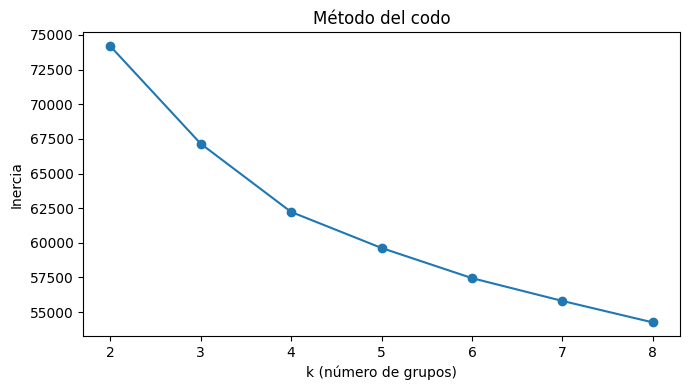

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(list(valores_k), inercias, marker='o')
plt.xlabel('k (número de grupos)')
plt.ylabel('Inercia')
plt.title('Método del codo')
plt.tight_layout()
plt.show()

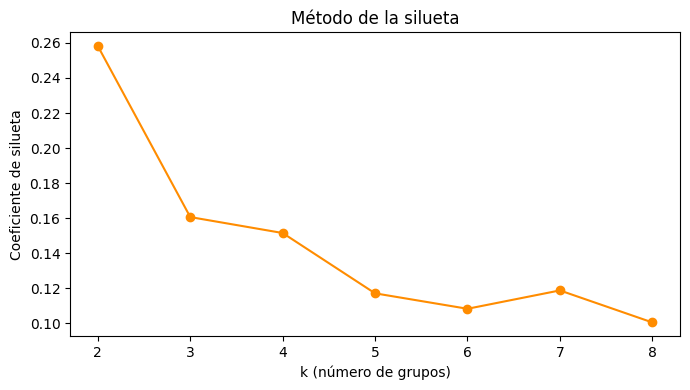

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(list(valores_k), siluetas, marker='o', color='darkorange')
plt.xlabel('k (número de grupos)')
plt.ylabel('Coeficiente de silueta')
plt.title('Método de la silueta')
plt.tight_layout()
plt.show()

A pesar de que k = 2 seria la mejor inercia y el mejor coeficiente de silueta, tener solo dos grupos me daria solo dos descripciones como alta y baja, y como pudimos ver en las practicas anteriores  la gran mayoria de nuestros datos quedarian en alta, lo que sesgaria mucho nuestros resultados, por lo que entonces usaremo 3 y 4 grupos

### Resultados de kmeans con k=3 y k=4

In [10]:
#usamos kmeans con 3 clusters, 10 inicios aleatorios y un random state para que siempre nos de el mismo resultado
km3 = KMeans(n_clusters=3, n_init=10, random_state=42)
#entrenamos el modelo con los datos
km3.fit(datos_esc)

#vemos cuantas personas hay en cada grupo
print(pd.Series(km3.labels_).value_counts().sort_index())
#vemos el promedio de cada variable para cada grupo
perfil_k3 = datos_km.groupby(km3.labels_).mean().round(2).T 
print(perfil_k3)

0    3545
1    3464
2    1010
Name: count, dtype: int64
             0     1     2
cb_P5_1   9.24  8.09  6.10
cb_P5_2   9.16  8.25  6.23
cb_P5_3   9.34  8.38  6.51
cb_P5_4   9.46  8.59  6.64
cb_P5_5   9.28  8.30  6.36
cb_P5_6   8.98  7.48  5.56
cb_P5_7   6.85  4.48  3.66
cb_P5_8   9.46  8.49  6.62
cb_P5_9   9.50  8.43  6.74
cb_P5_10  9.08  7.55  6.25
cb_P5_11  8.73  6.60  5.94
cb_P5_12  8.42  6.30  5.81


Al dividirlo en 3 grupos, vemos que principalmente, suponiendo que divide alto, medio y bajo, la gran mayoría quedan en alta y media, como habiamos visto antes, el promedio de la satisfaccion con la seguridad es la variable mas baja, en absolutamente todos los niveles algo que llama mucho la atencion es que en el bajo, practicamente todas las preguntas con excepcion de la de seguridad quedan cercanas a 6

In [11]:
#usamos kmeans con 4 clusters, 10 inicios aleatorios y un random state para que siempre nos de el mismo resultado
km4 = KMeans(n_clusters=4, n_init=10, random_state=42)
#entrenamos el modelo con los datos
km4.fit(datos_esc)

#vemos cuantas personas hay en cada grupo
print(pd.Series(km4.labels_).value_counts().sort_index())
#vemos el promedio de cada variable para cada grupo
perfil_k4 = datos_km.groupby(km4.labels_).mean().round(2).T
print(perfil_k4)

0    3090
1    2913
2     859
3    1157
Name: count, dtype: int64
             0     1     2     3
cb_P5_1   9.35  7.93  5.96  8.46
cb_P5_2   9.29  8.06  6.13  8.52
cb_P5_3   9.47  8.19  6.38  8.75
cb_P5_4   9.57  8.42  6.50  8.90
cb_P5_5   9.41  8.07  6.23  8.75
cb_P5_6   9.12  7.38  5.42  7.82
cb_P5_7   6.81  5.61  3.59  2.60
cb_P5_8   9.53  8.41  6.45  8.76
cb_P5_9   9.56  8.42  6.55  8.64
cb_P5_10  9.10  8.00  6.16  6.87
cb_P5_11  8.74  7.78  5.90  4.41
cb_P5_12  8.42  7.55  5.81  3.94


Al dividirlo en 4 grupos, vemos quue el grupo 1, 2 y 3 son las personas con satisfccion alta, media y baja respectivamente, el que cambia realmente es el grupo 4, que como se puede ver el grupo 3 tiene 5.96 de satisfacción con la vida, pero el grupo 4 tiene 8.46 de satisfacción con la vida, pero podemos ver que su satisfaccion con la seguridad ciudadana es la mas baja de todos los grupos 2.60, tambien las preguntas que tan satisfecho esta con su ciudad y que tan satisfecho esta con su país, son las más bajas de todos los grupos, por lo que podemos decir que el grupo 4 son personas con alta satisfacción con la vida, pero muy insatisfechos con el lugar donde viven